# 6주차 이론 예제 — 워크북 코드를 위한 파이썬 문법

**인공지능과 데이터 활용 · 고객 리뷰 데이터의 가공 및 분석**

이론 시간에 **한 셀씩 실행하며** 설명하는 노트북입니다. 워크북 0~4에서 쓰는 코드를 아주 작은 예제로 쪼개
"이 한 줄이 무엇을 하는지"를 직접 확인합니다. 외부 데이터 없이 바로 실행됩니다(약 20초).

| 절 | 문법·개념 | 노션 이론 | 쓰이는 워크북 셀 |
|---|---|---|---|
| T1 | 문자열·리스트·딕셔너리, f-string | 3.1 | 전체 |
| T2 | `in`, `sum(제너레이터)`, 조건 표현식, `def` 함수 | 3.4 | 2-2 규칙 v1·v2 |
| T3 | 정규표현식 `re.sub` · `re.findall` · `re.search` | 3.3 | 0-4 정제, 1-3 정리, 1-5 어절 |
| T4 | `Counter.most_common` | 3.3 | 1-5 어절 빈도 |
| T5 | pandas: `read_csv` 옵션, `.str`, 불리언 필터 `~ & \|`, 중복, `map`/`lambda`, `np.where`, `groupby`, `crosstab` | 3.2·3.3 | 0-3 ~ 0-5, 1-1 ~ 1-4, 4-1 |
| T6 | `hashlib.md5` 파일 지문 | 3.2 | 0-5 재현성 확인 |
| T7 | `TfidfVectorizer`: 글자 조각, `fit` vs `transform` | 3.5 | 3-2 ~ 3-4 |
| T8 | `LogisticRegression`: 가중치, `predict_proba`, 시그모이드 직접 계산 | 3.5 | 3-3 ~ 3-6 |
| T9 | 혼동행렬·정확도·정밀도·재현율·일치율 | 3.6 | 4-1 ~ 4-2 |

**사용법:** 위에서부터 `Shift+Enter`로 한 셀씩 실행합니다. 각 절 끝의 **직접 바꿔 보기**에서 값을 바꿔 다시 실행해 보세요.

## 0. 준비

In [1]:
!pip -q --disable-pip-version-check install koreanize-matplotlib      # 그래프 한글 표시 (처음 한 번)

In [2]:
import io, re, hashlib                  # 파이썬 기본 모듈: 파일처럼 다루기, 정규표현식, 해시
from collections import Counter         # 개수 세기 도구
import numpy as np                      # 숫자 계산
import pandas as pd                     # 표(DataFrame) 다루기
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")   # 버전 차이 경고 숨김
import koreanize_matplotlib
plt.rcParams["axes.unicode_minus"] = False
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.0.2


> **문법** `import 모듈` 은 도구 상자를 가져오는 것, `import pandas as pd` 는 줄여 부를 이름(`pd`)을 붙이는 것,
> `from collections import Counter` 는 상자 안의 도구 하나만 꺼내 오는 것입니다. `#` 뒤는 **주석**(실행되지 않는 설명)입니다.

---
## T1. 문자열 · 리스트 · 딕셔너리
후기 한 줄은 **문자열(str)**, 여러 후기는 **리스트(list)**, "별점 → 라벨"처럼 짝지은 정보는 **딕셔너리(dict)** 입니다.

| 문법 | 뜻 | 예 → 결과 |
|---|---|---|
| `"..."` / `'...'` | 문자열 | `"좋아요"` |
| `s.strip()` | 앞뒤 공백 제거 | `"  좋아요 ".strip()` → `"좋아요"` |
| `s.replace(a, b)` | a를 b로 바꾸기 | `"별루".replace("루","로")` → `"별로"` |
| `len(s)` | 글자 수 | `len("좋아요")` → `3` |
| `[a, b, c]` | 리스트 | `reviews[0]` → 첫 번째 (번호는 **0부터**) |
| `{키: 값}` | 딕셔너리 | `{4: "긍정"}[4]` → `"긍정"` |
| `f"{x}"` | f-문자열: 변수를 글 안에 넣기 | `f"{0.8867:.3f}"` → `"0.887"` |

In [3]:
review = "  배송이 너어어무 느림  "           # 실제 수업 데이터 R059 (앞뒤 공백을 일부러 붙임)
print(repr(review))                            # repr: 공백까지 보이게 출력
clean = review.strip()                         # 앞뒤 공백 제거 → 새 문자열을 돌려줌 (원본은 그대로)
print(repr(clean), "| 글자 수:", len(clean))
print("느림" in clean, "| 좋아" in clean)      # in: 부분 문자열이 들어 있으면 True

'  배송이 너어어무 느림  '
'배송이 너어어무 느림' | 글자 수: 11
True False


In [4]:
reviews = ["배송이 너어어무 느림", "세팅력이 우수합니다", "접착성 완전 안좋아요ㅜ"]   # 리스트
print("개수:", len(reviews), "| 첫 번째:", reviews[0], "| 마지막:", reviews[-1])

for i, r in enumerate(reviews, start=1):       # for 반복 + enumerate: 번호와 값을 함께
    print(f"{i}번 후기 ({len(r)}자): {r}")      # f-문자열 안의 {} 에 변수·식이 들어감

lengths = [len(r) for r in reviews]            # 리스트 컴프리헨션: [식 for 변수 in 목록]
print("길이 목록:", lengths)

개수: 3 | 첫 번째: 배송이 너어어무 느림 | 마지막: 접착성 완전 안좋아요ㅜ
1번 후기 (11자): 배송이 너어어무 느림
2번 후기 (10자): 세팅력이 우수합니다
3번 후기 (12자): 접착성 완전 안좋아요ㅜ
길이 목록: [11, 10, 12]


In [5]:
label_of = {1: "부정", 2: "부정", 4: "긍정", 5: "긍정"}   # 딕셔너리: 별점 → 라벨
print(label_of[5], label_of[2])
print(label_of.get(3, "없음"))                  # .get(키, 기본값): 키가 없어도 오류 대신 기본값
acc = 266 / 300
print(f"정확도 = {acc:.3f}  ({acc:.1%})")      # :.3f 소수 셋째 자리, :.1% 퍼센트

긍정 부정
없음
정확도 = 0.887  (88.7%)


**직접 바꿔 보기** ① `reviews`에 후기 하나를 추가하고 다시 실행 ② `label_of`에 `3: "중립"`을 넣고 `.get(3, ...)` 결과 확인

---
## T2. `in` · `sum` · 조건 표현식 · 함수 — 키워드 규칙의 뼈대
워크북 2의 규칙 함수는 이 네 가지 문법만으로 만들어집니다.

| 문법 | 뜻 |
|---|---|
| `w in text` | 단어 `w`가 문장에 들어 있으면 `True`, 아니면 `False` |
| `True + True` | 파이썬에서 `True`=1, `False`=0 → 더하면 **개수** |
| `sum(식 for w in 목록)` | 목록의 각 원소로 식을 계산해 모두 더함 (제너레이터 식) |
| `A if 조건 else B` | 조건이 참이면 A, 거짓이면 B (한 줄 if) |
| `def 이름(입력):` ... `return 값` | 함수 정의. 들여쓰기(4칸)한 줄들이 함수 몸통 |

In [6]:
text = "배송 빠르고 포장도 좋아요 추천"
POS = ["좋아", "만족", "추천", "빠르"]

print([w in text for w in POS])        # 단어별 True/False
print(True + True + False)             # True=1, False=0
p = sum(w in text for w in POS)        # 들어 있는 긍정 단어 개수
print("긍정 단어 개수 p =", p)

[True, False, True, True]
2
긍정 단어 개수 p = 3


In [7]:
POS = ["좋아", "좋고", "만족", "추천", "최고", "맛있", "예뻐", "빠르"]
NEG = ["별로", "실망", "불량", "고장", "반품", "냄새", "불편", "최악"]

def rule(text):                                   # 함수 정의: 입력 text
    p = sum(w in text for w in POS)               # 긍정 단어 수
    n = sum(w in text for w in NEG)               # 부정 단어 수
    return "긍정" if p > n else ("부정" if n > p else "중립")   # 조건 표현식 2번 겹침

for t in ["배송 빠르고 좋아요", "냄새가 너무 나요", "세팅력이 우수합니다", "접착성 완전 안좋아요ㅜ"]:
    print(f"{rule(t)}  ←  {t}")

긍정  ←  배송 빠르고 좋아요
부정  ←  냄새가 너무 나요
중립  ←  세팅력이 우수합니다
긍정  ←  접착성 완전 안좋아요ㅜ


**관찰** `세팅력이 우수합니다` 는 단어를 못 찾아 **중립**, `안좋아요` 는 `좋아`가 들어 있어 **긍정**으로 잘못 판정됩니다(이론 3.4의 실패 유형).
아래처럼 **부정 표현**에 가중치를 주면 고칠 수 있습니다(워크북 2 규칙 v2의 아이디어).

In [8]:
NEGATION = ["안좋", "안 좋", "좋지 않", "다시는"]

def rule_v2(text):
    p = sum(w in text for w in POS)
    n = sum(w in text for w in NEG) + 2 * sum(w in text for w in NEGATION)   # 부정 표현은 +2점
    return "긍정" if p > n else ("부정" if n > p else "중립")

print(rule("접착성 완전 안좋아요ㅜ"), "→", rule_v2("접착성 완전 안좋아요ㅜ"))

긍정 → 부정


**직접 바꿔 보기** ① `POS`에 `"우수"`를 넣어 `세팅력이 우수합니다`가 긍정이 되는지 확인 ② `return` 줄의 들여쓰기를 지우고 실행하면 어떤 오류가 나는지 확인(`IndentationError`)

---
## T3. 정규표현식 `re` — 글자 패턴으로 찾고 바꾸기
| 기호 | 뜻 | 예 |
|---|---|---|
| `r"..."` | raw 문자열: `\`를 그대로 둠 (정규표현식은 항상 `r`을 붙인다) | `r"\s+"` |
| `\s` | 공백 문자(스페이스·탭·줄바꿈) | |
| `+` / `*` / `{2,}` | 1번 이상 / 0번 이상 / 2번 이상 반복 | `\s+` = 공백 1개 이상 |
| `.` | 아무 글자 하나 | |
| `( )` / `\1` | 묶어서 기억 / 기억한 것을 다시 사용 | `(.)\1{2,}` = 같은 글자 3번 이상 |
| `[가-힣]` | 한글 한 글자 (범위) | `[가-힣A-Za-z0-9]+` = 한글·영문·숫자 덩어리 |
| `a\|b` | a 또는 b | `@\|https?://` |
| `\d` | 숫자 한 글자 | `\d{3,4}` = 숫자 3~4개 |
| `?` | 앞 글자가 있어도 되고 없어도 됨 | `https?` = http 또는 https |

| 함수 | 하는 일 |
|---|---|
| `re.sub(패턴, 바꿀것, 문장)` | 패턴을 찾아 바꾼 새 문장 |
| `re.findall(패턴, 문장)` | 패턴에 맞는 부분을 모두 리스트로 |
| `re.search(패턴, 문장)` | 처음 맞는 곳(없으면 `None`) |

In [9]:
t = "대구지역~~~~아직    제품과 만나지 못했네요 ㅠㅠㅠㅠ"
t1 = re.sub(r"\s+", " ", t)                    # 공백 여러 개 → 1칸
t2 = re.sub(r"(.)\1{2,}", r"\1\1", t1)          # 같은 글자 3번 이상 → 2번 (~~~~ → ~~, ㅠㅠㅠㅠ → ㅠㅠ)
print(t); print(t1); print(t2)

대구지역~~~~아직    제품과 만나지 못했네요 ㅠㅠㅠㅠ
대구지역~~~~아직 제품과 만나지 못했네요 ㅠㅠㅠㅠ
대구지역~~아직 제품과 만나지 못했네요 ㅠㅠ


In [10]:
s = "배송빠르고 굿!! 가성비 최고^^ 2개 더 샀어요"
print(re.findall(r"[가-힣A-Za-z0-9]+", s))      # 기호를 빼고 어절만 꺼내기 (워크북 1-5)
print(s.split())                                 # 비교: 공백으로만 자르면 '굿!!', '최고^^' 처럼 기호가 붙음

['배송빠르고', '굿', '가성비', '최고', '2개', '더', '샀어요']
['배송빠르고', '굿!!', '가성비', '최고^^', '2개', '더', '샀어요']


In [11]:
PII = r"(?:\d{2,4}[-.\s]?\d{3,4}[-.\s]?\d{4}|@|https?://|www\.|\.com)"   # 워크북 0-4의 개인정보 의심 패턴
for t in ["연락주세요 010-1234-5678", "메일 abc@naver.com 으로", "배송 빠르고 좋아요", "11월6에 시켰는데 11월16일에 왔네요"]:
    m = re.search(PII, t)
    print("제외" if m else "통과", "|", t, "| 찾은 부분:", m.group() if m else "-")

제외 | 연락주세요 010-1234-5678 | 찾은 부분: 010-1234-5678
제외 | 메일 abc@naver.com 으로 | 찾은 부분: @
통과 | 배송 빠르고 좋아요 | 찾은 부분: -
통과 | 11월6에 시켰는데 11월16일에 왔네요 | 찾은 부분: -


> `(?: ... )` 는 묶기만 하고 기억하지 않는 괄호, `[-.\s]?` 는 "하이픈·점·공백 중 하나가 있어도 되고 없어도 됨"입니다.
> 마지막 예처럼 날짜는 통과합니다. 규칙은 완벽하지 않으므로 **사람이 읽다가 발견하면 알린다**는 원칙을 함께 둡니다.

**직접 바꿔 보기** ① `(.)\1{2,}` 를 `(.)\1{1,}` 로 바꾸면 무엇이 달라지나? ② `[가-힣]+` 만 쓰면 `2개`는 어떻게 되나?

---
## T4. `Counter` — 개수 세기

In [12]:
words = ["좋아요", "재구매", "좋아요", "너무", "좋아요", "재구매", "그냥"]
cnt = Counter(words)                  # 각 값이 몇 번 나왔는지 세는 사전
print(cnt)
print(cnt.most_common(2))             # 가장 많은 2개: [(값, 횟수), ...]
print(cnt["좋아요"], cnt["없는말"])    # 없는 키는 0

Counter({'좋아요': 3, '재구매': 2, '너무': 1, '그냥': 1})
[('좋아요', 3), ('재구매', 2)]
3 0


**쓰이는 곳** 워크북 1-5 `Counter(words).most_common(15)` — 긍정·부정 후기에서 자주 나온 어절 15개.

---
## T5. pandas — 표(DataFrame) 다루기
워크북에서 가장 많이 쓰는 도구입니다. **DataFrame** = 엑셀 표, **Series** = 표의 한 열.

### T5-1. `read_csv` 옵션 — 탭 구분·헤더 없는 파일
원자료 `naver_shopping.txt`는 `별점<탭>후기` 형식이고 **열 이름 줄이 없습니다**. 같은 모양의 작은 예로 연습합니다.

In [13]:
raw_text = "5\t배공빠르고 굿\n2\t택배가 엉망이네용\n5\t아주좋아요 바지 정말 좋아서2개 더 구매했어요\n"   # \t = 탭, \n = 줄바꿈

bad = pd.read_csv(io.StringIO(raw_text), sep="\t")      # header 지정 없음 → 첫 줄을 열 이름으로 착각!
print("잘못 읽은 열 이름:", list(bad.columns), "| 행 수:", len(bad))

df = pd.read_csv(io.StringIO(raw_text), sep="\t", header=None, names=["rating", "review_text"])
print("바르게 읽은 열 이름:", list(df.columns), "| 행 수:", len(df))
df

잘못 읽은 열 이름: ['5', '배공빠르고 굿'] | 행 수: 2
바르게 읽은 열 이름: ['rating', 'review_text'] | 행 수: 3


,rating,review_text
0,5,배공빠르고 굿
1,2,택배가 엉망이네용
2,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요


| 옵션 | 뜻 |
|---|---|
| `io.StringIO(문자열)` | 문자열을 파일처럼 읽게 해 줌 (워크북에서는 내려받은 바이트에 `io.BytesIO`) |
| `sep="\t"` | 열 구분자가 탭 (기본값은 쉼표 `,`) |
| `header=None` | 첫 줄도 데이터다 (열 이름 줄이 없다) |
| `names=[...]` | 열 이름을 직접 붙임 |
| `encoding="utf-8-sig"` | 엑셀용 BOM이 붙은 UTF-8 CSV를 깨끗하게 읽음 (워크북 1-1) |

### T5-2. 열 꺼내기 · `.str` · 새 열 만들기

In [14]:
df = pd.DataFrame({
    "review_id": ["R001", "R002", "R003", "R004", "R005", "R006"],
    "rating":    [4, 4, 2, 2, 5, 1],
    "review_text": ["오리상태도 좋고 밋도 있어여", "세팅력이 우수합니다", "  패드장착이 안되어 왔구요~~~~ ",
                    "패드장착이 안되어 왔구요~~~~", "배송 빠르고 좋아요", None],
})
print(df.shape)                         # (행 수, 열 수)
df["rating"]                            # 열 하나 = Series

(6, 3)


0    4
1    4
2    2
3    2
4    5
5    1
Name: rating, dtype: int64

In [15]:
print(df["review_text"].isna())                         # 결측(None/NaN)이면 True
df = df.dropna(subset=["review_text"]).copy()           # 결측 행 제거 (.copy(): 새 표로 확정)
df["text"] = df["review_text"].str.strip()              # .str: 열 전체에 문자열 함수를 한꺼번에
df["length"] = df["text"].str.len()
df["has_좋"] = df["text"].str.contains("좋")            # 포함 여부 True/False
df

0    False
1    False
2    False
3    False
4    False
5     True
Name: review_text, dtype: bool


,review_id,rating,review_text,text,length,has_좋
0,R001,4,오리상태도 좋고 밋도 있어여,오리상태도 좋고 밋도 있어여,15,True
1,R002,4,세팅력이 우수합니다,세팅력이 우수합니다,10,False
2,R003,2,패드장착이 안되어 왔구요~~~~,패드장착이 안되어 왔구요~~~~,17,False
3,R004,2,패드장착이 안되어 왔구요~~~~,패드장착이 안되어 왔구요~~~~,17,False
4,R005,5,배송 빠르고 좋아요,배송 빠르고 좋아요,10,True


> **원문 보존**: `review_text`는 그대로 두고 `text`라는 **새 열**에 정리 결과를 넣었습니다. `df["새열"] = 값` 이 열 만들기입니다.

### T5-3. 불리언 필터 — 조건으로 행 고르기
| 문법 | 뜻 |
|---|---|
| `df[조건]` | 조건이 `True`인 행만 |
| `~조건` | NOT (뒤집기) |
| `(조건1) & (조건2)` | AND — **괄호 필수** |
| `(조건1) \| (조건2)` | OR |
| `s.between(a, b)` | a 이상 b 이하 |
| `s.isin(목록)` | 목록 안에 있으면 True |

In [16]:
print(df[df["rating"] >= 4][["review_id", "text"]], "\n")                 # 별점 4 이상
print(df[~df["text"].str.contains("좋")][["review_id", "text"]], "\n")    # '좋'이 없는 행 (~ = NOT)
print(df[(df["rating"] <= 2) & (df["length"].between(10, 150))][["review_id", "length"]], "\n")
print(df[df["review_id"].isin(["R001", "R005"])][["review_id", "text"]])

  review_id             text
0      R001  오리상태도 좋고 밋도 있어여
1      R002       세팅력이 우수합니다
4      R005       배송 빠르고 좋아요 

  review_id               text
1      R002         세팅력이 우수합니다
2      R003  패드장착이 안되어 왔구요~~~~
3      R004  패드장착이 안되어 왔구요~~~~ 

  review_id  length
2      R003      17
3      R004      17 

  review_id             text
0      R001  오리상태도 좋고 밋도 있어여
4      R005       배송 빠르고 좋아요


### T5-4. 중복 — `duplicated` · `drop_duplicates(keep=...)`

In [17]:
print(df["text"].duplicated())                                          # 두 번째부터 True
print("keep='first' →", df.drop_duplicates(subset=["text"], keep="first")["review_id"].tolist())
print("keep=False   →", df.drop_duplicates(subset=["text"], keep=False)["review_id"].tolist())

0    False
1    False
2    False
3     True
4    False
Name: text, dtype: bool
keep='first' → ['R001', 'R002', 'R003', 'R005']
keep=False   → ['R001', 'R002', 'R005']


> R003과 R004는 앞뒤 공백만 다르고 같은 문장입니다. `strip`으로 정리한 `text`에서는 중복으로 잡힙니다.
> 워크북 0은 도배·복사 후기를 아예 빼려고 **`keep=False`(중복된 문장은 하나도 남기지 않음)** 를 씁니다.

### T5-5. `map` · `lambda` · `np.where` — 값 바꾸기
| 문법 | 뜻 |
|---|---|
| `s.map(딕셔너리)` | 값을 사전에서 찾아 바꿈 |
| `s.map(함수)` | 각 값에 함수를 적용 (워크북 2: `df["text"].map(rule)`) |
| `lambda r: 식` | 이름 없는 한 줄 함수 |
| `np.where(조건, A, B)` | 조건이 참이면 A, 거짓이면 B (열 전체에 한 번에) |

In [18]:
df["label_dict"]   = df["rating"].map({1: "부정", 2: "부정", 4: "긍정", 5: "긍정"})
df["label_lambda"] = df["rating"].map(lambda r: "긍정" if r >= 4 else "부정")
df["label_where"]  = np.where(df["rating"] >= 4, "긍정", "부정")
df["rule"]         = df["text"].map(rule)                     # T2에서 만든 함수를 열 전체에 적용
df[["review_id", "rating", "label_dict", "label_lambda", "label_where", "rule"]]

,review_id,rating,label_dict,label_lambda,label_where,rule
0,R001,4,긍정,긍정,긍정,긍정
1,R002,4,긍정,긍정,긍정,중립
2,R003,2,부정,부정,부정,중립
3,R004,2,부정,부정,부정,중립
4,R005,5,긍정,긍정,긍정,긍정


### T5-6. 집계 — `value_counts` · `groupby` · `crosstab` · 층화 추출

In [19]:
big = pd.DataFrame({"rating": [1]*6 + [2]*6 + [4]*6 + [5]*12, "id": range(30)})   # 별점 5가 많은 표
print(big["rating"].value_counts().sort_index().to_dict())                       # 값별 개수

s1 = big.groupby("rating").sample(n=3, random_state=2026)    # 별점마다 3개씩 무작위 (층화 추출)
s2 = big.groupby("rating").sample(n=3, random_state=2026)    # 같은 시드 → 같은 결과
s3 = big.groupby("rating").sample(n=3, random_state=7)       # 다른 시드 → 다른 결과
print("층화 추출:", s1["rating"].value_counts().sort_index().to_dict())
print("같은 시드 같은 결과?", s1["id"].tolist() == s2["id"].tolist(), "| 다른 시드?", s1["id"].tolist() == s3["id"].tolist())
print("그냥 12개 무작위:", big.sample(n=12, random_state=2026)["rating"].value_counts().sort_index().to_dict())

{1: 6, 2: 6, 4: 6, 5: 12}
층화 추출: {1: 3, 2: 3, 4: 3, 5: 3}
같은 시드 같은 결과? True | 다른 시드? False
그냥 12개 무작위: {1: 1, 2: 4, 4: 2, 5: 5}


In [20]:
print(df.groupby("label_dict")["length"].mean().round(1))    # 그룹별 평균 길이 (워크북 1-4)
pd.crosstab(df["label_dict"], df["rule"], margins=True, margins_name="합계")   # 교차표 (워크북 4-1)

label_dict
긍정    11.7
부정    17.0
Name: length, dtype: float64


rule,긍정,중립,합계
label_dict,,,
긍정,2,1,3
부정,0,2,2
합계,2,3,5


| 문법 | 뜻 |
|---|---|
| `s.value_counts()` | 값별 개수 |
| `df.groupby("열")["다른열"].mean()` | 열 값별로 묶어서 평균 |
| `df.groupby("열").sample(n=, random_state=)` | 묶음마다 n개씩 무작위 (**층화 추출**), 시드가 같으면 결과도 같다 |
| `pd.crosstab(행, 열, margins=True)` | 두 열의 조합별 개수표 (합계 포함) |

**직접 바꿔 보기** ① `random_state`를 바꿔 결과가 달라지는지 ② `keep="last"`는 어떤 행을 남기는지

---
## T6. `hashlib.md5` — 파일 지문으로 같은 데이터인지 확인

In [21]:
a = "review_id,rating\nR001,4\n".encode("utf-8")      # 문자열 → 바이트
b = "review_id,rating\nR001,4\n".encode("utf-8")
c = "review_id,rating\nR001,5\n".encode("utf-8")      # 한 글자만 다름
for name, x in [("a", a), ("b", b), ("c", c)]:
    print(name, hashlib.md5(x).hexdigest())

a 44458b8143658c82d6a39ddff701f00a
b 44458b8143658c82d6a39ddff701f00a
c 099ccb74836f4ea973ba3b1e26034386


> 내용이 **한 글자라도** 다르면 지문이 완전히 달라집니다. 워크북 0에서는 내가 만든 300건 CSV의 MD5가
> 수업 데이터(`826290503dfc1ab898089886d3225ba0`)와 같으면 **같은 규칙·같은 시드로 재현했다**는 증거가 됩니다.
> 실제 파일은 `hashlib.md5(open("파일", "rb").read()).hexdigest()` 로 계산합니다(`"rb"` = 바이트로 읽기).

---
## T7. TF-IDF — 문장을 숫자로 바꾸기

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))   # 어절 안에서 2~3글자 조각
print(vec.build_analyzer()("배송 빠르고"))                        # 한 문장이 어떤 조각으로 잘리는지

[' 배', '배송', '송 ', ' 배송', '배송 ', ' 빠', '빠르', '르고', '고 ', ' 빠르', '빠르고', '르고 ']


| 옵션 | 뜻 |
|---|---|
| `analyzer="char_wb"` | 글자 단위, 어절(word) 경계 안에서 자르기 (앞뒤에 공백 표시) |
| `ngram_range=(2, 4)` | 2·3·4글자 조각을 모두 사용 (워크북은 2~4) |
| `min_df=5` | 5개 미만의 문장에만 나온 조각은 버림 (워크북 설정, 아래 작은 예에서는 생략) |

In [23]:
docs = ["배송 빠르고 좋아요", "배송 늦고 별로", "배송 빠르고 별로", "좋아요 추천"]
X = vec.fit_transform(docs)          # fit: 조각 사전 만들기 + transform: 숫자로 바꾸기
print("모양(문장 수, 조각 수):", X.shape)
tfidf = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(), index=docs).round(2)
tfidf[[" 배송", "배송", " 좋아", "좋아요", "별로", " 늦", "추천"]]

모양(문장 수, 조각 수): (4, 33)


,배송,배송,좋아,좋아요,별로,늦,추천
배송 빠르고 좋아요,0.20,0.20,0.24,0.24,0.00,0.00,0.00
배송 늦고 별로,0.21,0.21,0.00,0.00,0.26,0.32,0.00
배송 빠르고 별로,0.21,0.21,0.00,0.00,0.26,0.00,0.00
좋아요 추천,0.00,0.00,0.26,0.26,0.00,0.00,0.33


> 네 문장 중 세 문장에 나오는 `배송`은 값이 **작고**, 한두 문장에만 나오는 `별로`·`늦`·`추천`은 값이 **큽니다** → 그 문장의 특징이 되는 조각일수록 큰 값(TF-IDF).

In [24]:
new = vec.transform(["배송 빠르고 최고"])      # 새 문장은 transform만! (사전은 학습 때 만든 것 그대로)
print("새 문장에서 0이 아닌 조각:", [vec.get_feature_names_out()[j] for j in new.nonzero()[1]])
print("'최고'는 사전에 없어서 무시된다 →", "최고" in vec.vocabulary_)

새 문장에서 0이 아닌 조각: [' 배', ' 배송', ' 빠', ' 빠르', '고 ', '르고', '르고 ', '배송', '배송 ', '빠르', '빠르고', '송 ']
'최고'는 사전에 없어서 무시된다 → False


> **`fit_transform` vs `transform`** — 학습 문장으로 사전을 만들 때만 `fit`을 하고, 새 문장(수업 300건)에는 `transform`만 씁니다.
> 새 문장으로 다시 `fit`하면 조각 번호가 바뀌어 학습한 가중치와 맞지 않습니다(워크북 3의 자주 하는 실수).

---
## T8. 로지스틱 회귀 — 가중치를 배우고 확률로 바꾸기
실제 수업 후기 12개로 아주 작은 분류기를 학습해 봅니다(워크북 3은 같은 방법으로 199,700건을 학습).

In [25]:
from sklearn.linear_model import LogisticRegression

train_text = ["배송 빠르고 좋아요", "아주 만족합니다 추천", "가성비 최고 재구매", "깔끔하고 좋아요",
              "튼튼하고 편해요", "맛있어요 또 살게요",
              "별로예요 반품할게요", "냄새가 너무 나요", "실망입니다 비추", "배송이 너무 느림",
              "불량이라 교환했어요", "안좋아요 다시는 안사요"]
train_y = [1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0]          # 1 = 긍정, 0 = 부정

vec2 = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
X_train = vec2.fit_transform(train_text)               # 학습 문장 → 숫자 (fit)
model = LogisticRegression(C=10).fit(X_train, train_y)  # 가중치 학습 (C: 클수록 학습 데이터에 더 강하게 맞춤)
print("조각 수:", X_train.shape[1])

조각 수: 182


In [26]:
names = vec2.get_feature_names_out()
w = pd.Series(model.coef_[0], index=names).sort_values()   # coef_: 조각별 가중치 (+ 긍정 / − 부정)
print("부정 쪽 조각:", w.head(6).round(2).to_dict())
print("긍정 쪽 조각:", w.tail(6).round(2).to_dict())

부정 쪽 조각: {' 안': -0.79, ' 너': -0.65, ' 너무': -0.65, '너무 ': -0.65, '너무': -0.65, '무 ': -0.65}
긍정 쪽 조각: {'있어요': 0.47, '하고': 0.69, '하고 ': 0.69, ' 좋': 0.72, ' 좋아': 0.72, '고 ': 1.1}


In [27]:
test = ["포장도 좋아요 추천", "냄새 나고 별로", "그냥 그래요", "안좋아요"]
proba = model.predict_proba(vec2.transform(test))        # [부정 확률, 긍정 확률] 두 열
print(proba.round(3))
for t, p in zip(test, proba[:, 1]):                       # [:, 1] = 모든 행의 두 번째 열(긍정 확률)
    print(f"{p:.3f} → {'긍정' if p >= 0.5 else '부정'}  | {t}")

[[0.21  0.79 ]
 [0.683 0.317]
 [0.539 0.461]
 [0.615 0.385]]
0.790 → 긍정  | 포장도 좋아요 추천
0.317 → 부정  | 냄새 나고 별로
0.461 → 부정  | 그냥 그래요
0.385 → 부정  | 안좋아요


### T8-1. 확률은 어떻게 계산되나 — 직접 계산해서 확인
$z = b + \sum_i w_i x_i$ (가중치 × TF-IDF 값의 합), $P(\text{긍정}) = \dfrac{1}{1+e^{-z}}$ (시그모이드)

z = [ 1.327 -0.77  -0.158 -0.47 ]
직접 계산: [0.79  0.317 0.461 0.385] | sklearn: [0.79  0.317 0.461 0.385] | 같은가? True


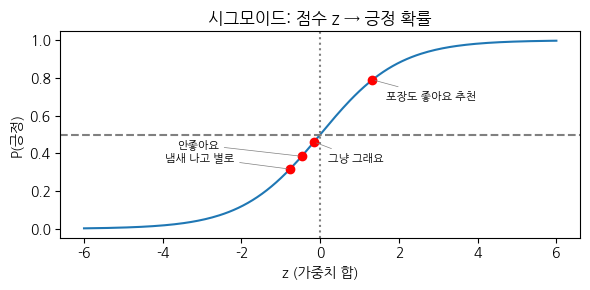

In [28]:
Xt = vec2.transform(test).toarray()
z = Xt @ model.coef_[0] + model.intercept_[0]           # @ = 행렬 곱: 각 문장의 Σ(가중치 × 값) + 절편
p_manual = 1 / (1 + np.exp(-z))                          # 시그모이드
print("z =", z.round(3))
print("직접 계산:", p_manual.round(3), "| sklearn:", proba[:, 1].round(3), "| 같은가?", np.allclose(p_manual, proba[:, 1]))

zz = np.linspace(-6, 6, 200)
plt.figure(figsize=(6, 3))
plt.plot(zz, 1 / (1 + np.exp(-zz)))
plt.axhline(0.5, color="gray", ls="--"); plt.axvline(0, color="gray", ls=":")
plt.scatter(z, p_manual, color="red", zorder=3)
for k, (zi, pi, t) in enumerate(zip(z, p_manual, test)):
    plt.annotate(t, (zi, pi), textcoords="offset points", xytext=(-90 if k % 2 else 10, 6 if k % 2 else -14), fontsize=8,
                 arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
plt.title("시그모이드: 점수 z → 긍정 확률"); plt.xlabel("z (가중치 합)"); plt.ylabel("P(긍정)")
plt.tight_layout(); plt.show()

> 점수 z가 0이면 확률 0.5, 클수록 1에, 작을수록 0에 가까워집니다. **확률은 '얼마나 학습한 패턴과 닮았나'** 이지 '맞을 확률'이 아닙니다.
> 학습 문장에 없던 `그냥 그래요` 는 아는 조각이 거의 없어 0.5 근처(애매)가 됩니다.

> **작은 데이터의 함정**: 학습 문장 12개에서 `너무`는 부정 문장에만 나왔기 때문에 부정 단서가 되었습니다. *너무 좋아요* 도 부정 쪽으로 끌려갑니다. 긍정 쪽 1위 `고 `(빠르**고**·깔끔하**고**의 끝 글자)도 우연히 생긴 단서입니다.
> 단서가 우연이 아니라 일반적인 패턴이 되려면 많은 데이터가 필요합니다 → 워크북 3은 19만 9,700건으로 학습합니다.

**직접 바꿔 보기** ① `train_text`에 `"그냥 그래요"`를 부정(0)으로 추가해 다시 학습하면 확률이 어떻게 변하나? ② `test`에 문장을 추가해 보기

---
## T9. 평가 — 혼동행렬 · 정확도 · 정밀도 · 재현율 · 일치율

In [29]:
y_true = ["긍정", "긍정", "긍정", "긍정", "부정", "부정", "부정", "부정", "부정", "부정"]   # 별점 라벨(참고 정답)
y_ai   = ["긍정", "긍정", "긍정", "부정", "부정", "부정", "부정", "부정", "긍정", "부정"]   # AI 예측
y_rule = ["긍정", "긍정", "부정", "부정", "부정", "부정", "부정", "부정", "긍정", "부정"]   # 규칙 예측

print(pd.crosstab(pd.Series(y_true, name="별점"), pd.Series(y_ai, name="AI")))   # 혼동행렬

TP = sum(t == "부정" and p == "부정" for t, p in zip(y_true, y_ai))   # 부정을 부정으로 (zip: 두 목록을 짝지어 반복)
FP = sum(t == "긍정" and p == "부정" for t, p in zip(y_true, y_ai))   # 긍정인데 부정이라 함
FN = sum(t == "부정" and p == "긍정" for t, p in zip(y_true, y_ai))   # 부정인데 놓침
acc = sum(t == p for t, p in zip(y_true, y_ai)) / len(y_true)
print(f"\n정확도 {acc:.2f} | 부정 정밀도 {TP/(TP+FP):.2f} | 부정 재현율 {TP/(TP+FN):.2f}")

AI  긍정  부정
별점        
긍정   3   1
부정   1   5

정확도 0.80 | 부정 정밀도 0.83 | 부정 재현율 0.83


In [30]:
from sklearn.metrics import accuracy_score, classification_report
print("sklearn 정확도:", accuracy_score(y_true, y_ai))
print(classification_report(y_true, y_ai, digits=2, zero_division=0))

agree = sum(a == r for a, r in zip(y_ai, y_rule)) / len(y_ai)
both_wrong = sum(a == r != t for a, r, t in zip(y_ai, y_rule, y_true))
print(f"AI-규칙 일치율 {agree:.2f} — 그중 둘 다 틀린 경우 {both_wrong}건 → 일치율은 정확도가 아니다")

sklearn 정확도: 0.8
              precision    recall  f1-score   support

          긍정       0.75      0.75      0.75         4
          부정       0.83      0.83      0.83         6

    accuracy                           0.80        10
   macro avg       0.79      0.79      0.79        10
weighted avg       0.80      0.80      0.80        10

AI-규칙 일치율 0.90 — 그중 둘 다 틀린 경우 2건 → 일치율은 정확도가 아니다


| 지표 | 계산 | 질문 |
|---|---|---|
| 정확도 | 맞은 수 ÷ 전체 | 얼마나 맞혔나? |
| 정밀도(부정) | TP ÷ (TP+FP) | '불만'이라 한 것 중 진짜 불만은? |
| 재현율(부정) | TP ÷ (TP+FN) | 진짜 불만 중 몇 개를 찾았나? |
| 일치율 | 두 방법이 같은 답 ÷ 전체 | 두 방법이 얼마나 비슷한가? (둘 다 틀려도 일치) |

---
## 정리 — 이 노트북의 문법이 워크북 어디에 쓰이나
| 워크북 | 대표 코드 | 이 노트북 |
|---|---|---|
| 0 수집 | `read_csv(sep="\t", header=None, names=...)`, `drop_duplicates(keep=False)`, `~str.contains(PII)`, `groupby().sample()`, `hashlib.md5` | T5-1, T5-4, T3, T5-6, T6 |
| 1 정제·탐색 | `re.sub`, `.str.len()`, `groupby().mean()`, `re.findall` + `Counter` | T3, T5-2, T5-6, T4 |
| 2 규칙 | `sum(w in text ...)`, 조건 표현식, `def`, `.map(rule)` | T2, T5-5 |
| 3 AI | `TfidfVectorizer`, `fit_transform`/`transform`, `LogisticRegression`, `predict_proba[:, 1]`, `coef_` | T7, T8 |
| 4 평가 | `crosstab`, `classification_report`, 일치율 | T5-6, T9 |

➡️ 실습: `Week06_00_감성데이터수집_실습.ipynb` → `Week06_리뷰감성분석_실습.ipynb`